In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os, shutil, glob, zipfile, re

DRIVE_DIR   = "/content/drive/MyDrive/Corneal_v2"            # <- your upload folder
CSV_NAME    = "Final_Features_MultiLabel_updated.csv"
IMG_NAME    = "Disease_Cell_Images"                           # zip OR folder with this name
LOCAL_DIR   = "/content/data_v2"
IMAGE_DIR   = os.path.join(LOCAL_DIR, "images")
RESULTS_DIR = "/content/drive/MyDrive/CNN_results_v2"         # NEW results folder
os.makedirs(LOCAL_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)

CSV_PATH = os.path.join(DRIVE_DIR, CSV_NAME)
assert os.path.exists(CSV_PATH), f"CSV not found: {CSV_PATH}"

if not os.path.isdir(IMAGE_DIR):
    zip_path, folder_path = os.path.join(DRIVE_DIR, IMG_NAME + ".zip"), os.path.join(DRIVE_DIR, IMG_NAME)
    if os.path.exists(zip_path):
        print("Unzipping", zip_path); zipfile.ZipFile(zip_path).extractall(IMAGE_DIR)
    elif os.path.isdir(folder_path):
        print("Copying folder", folder_path); shutil.copytree(folder_path, IMAGE_DIR)
    else:
        raise FileNotFoundError(f"Put {IMG_NAME}.zip or the {IMG_NAME}/ folder inside {DRIVE_DIR}")

IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
ALL_IMGS = [p for p in glob.glob(os.path.join(IMAGE_DIR, "**", "*"), recursive=True)
            if p.lower().endswith(IMG_EXT) and "__MACOSX" not in p]
print("Images found (all sub-folders):", len(ALL_IMGS))
print("Example file names:", [os.path.relpath(p, IMAGE_DIR) for p in ALL_IMGS[:8]])

Unzipping /content/drive/MyDrive/Corneal_v2/Disease_Cell_Images.zip
Images found (all sub-folders): 1543
Example file names: ['Disease_Cell_Images/NEB-2023-08-15288 R_SP.jpg', 'Disease_Cell_Images/NEB-2022-04-13822 R_SP.jpg', 'Disease_Cell_Images/NEB-2024-06-16136 R_SP.jpg', 'Disease_Cell_Images/NEB-2023-04-14947 R_SP.jpg', 'Disease_Cell_Images/NEB-2025-09-17464 L_SP.jpg', 'Disease_Cell_Images/NEB-2023-03-14825 R_SP.jpg', 'Disease_Cell_Images/NEB-2023-03-14907 R_SP.jpg', 'Disease_Cell_Images/NEB-2025-12-17726 L_SP.jpg']


Match CSV records to image files

In [4]:
import pandas as pd
df = pd.read_csv(CSV_PATH)
print("CSV rows:", len(df))

def norm(s): return re.sub(r"[^a-z0-9]", "", str(s).lower())
def short_key(s):
    m = re.search(r"(\d{4,6})[\s_\-]*([LR])(?![A-Z])", str(s).upper())
    return f"{m.group(1)}{m.group(2)}" if m else None

full_map, short_map, dup = {}, {}, []
for p in ALL_IMGS:
    stem = os.path.splitext(os.path.basename(p))[0]
    k = norm(stem)
    if k in full_map: dup.append(stem)
    full_map.setdefault(k, p)
    sk = short_key(stem)
    if sk: short_map.setdefault(sk, []).append(p)

# pass 1: exact (normalised) name match
df["Img_Path"] = df["Tissue_ID"].map(lambda t: full_map.get(norm(t)))
# pass 2: tissue-number + eye fallback, only for images not already taken and only if unambiguous
taken = set(df["Img_Path"].dropna())
sk_rows = df[df["Img_Path"].isna()]["Tissue_ID"].map(short_key)
for i, k in sk_rows.items():
    cands = [p for p in short_map.get(k or "", []) if p not in taken]
    if len(cands) == 1 and (sk_rows == k).sum() == 1:
        df.at[i, "Img_Path"] = cands[0]; taken.add(cands[0])
unmatched = df[df["Img_Path"].isna()]
print(f"Matched: {df['Img_Path'].notna().sum()} / {len(df)}   | unmatched rows: {len(unmatched)}")
if dup: print("WARNING duplicate image names (first kept):", dup[:5])
if len(unmatched):
    print("Unmatched Tissue_IDs (first 15):", unmatched["Tissue_ID"].head(15).tolist())
used = set(df["Img_Path"].dropna())
print("Images not used by any CSV row:", len(set(ALL_IMGS) - used))
n_dup = df["Img_Path"].dropna().duplicated().sum()
print("Image used by >1 row:", n_dup)
assert n_dup == 0, "Two rows point to the same image - check file names"

# Stop if matching is clearly wrong
assert df["Img_Path"].notna().mean() > 0.9, "Less than 90% of rows matched an image - fix img matching before training!"
df = df[df["Img_Path"].notna()].reset_index(drop=True)
unmatched.to_csv(os.path.join(RESULTS_DIR, "unmatched_rows.csv"), index=False)

CSV rows: 1548
Matched: 1527 / 1548   | unmatched rows: 21
WARNING duplicate image names (first kept): ['NEB-2026-03-18084L_SP', 'NEB-2021-11 -13399 R_SP']
Unmatched Tissue_IDs (first 15): ['NEB-2020-09-12672 R', 'NEB-2020-09-12683 L', 'NEB-2020-10-12726 R', 'NEB-2020-10-12733 L', 'NEB-2022-10-14315 L', 'NEB-2022-10-14349 L', 'NEB-2023-02-14710 R', 'NEB-2023-04-14996 R', 'NEB-2023-08-15300 R', 'NEB-2024-06-16116 L', 'NEB-2024-06-16117 R', 'NEB-2024-06-16130 L', 'NEB-2024-08-16256 L', 'NEB-2024-08-16296 L', 'NEB-2025-09-17506 R']
Images not used by any CSV row: 16
Image used by >1 row: 0


Import machine learning libraries and check the GPU

In [5]:
import json, time, copy, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score,
                             roc_curve, hamming_loss, accuracy_score)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "NONE - turn on T4 GPU!")

device: cuda | GPU: Tesla T4


Configure the experiment and create cross-validation folds

In [6]:
BACKBONE = "densenet121"
PRETRAINED = True
IMG_W, IMG_H = 384, 288
EPOCHS, WARMUP_EPOCHS, PATIENCE = 30, 2, 7
BATCH_SIZE = 16
LR_HEAD, LR_BACKBONE, WEIGHT_DECAY = 1e-3, 1e-4, 1e-4
SEED = 42
N_FOLDS = 5
LABEL_COLS = ["FECD", "Guttata", "Folds", "PolyPleo", "LowCD"]
FEATURES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]

NUM_RUN   = os.path.join(RESULTS_DIR, "numbers_only")
IMG_RUN   = os.path.join(RESULTS_DIR, f"image_only_{BACKBONE}")
FUS_RUN   = os.path.join(RESULTS_DIR, f"fusion_{BACKBONE}")
FINAL_DIR = os.path.join(RESULTS_DIR, f"final_{BACKBONE}")
for d in (NUM_RUN, IMG_RUN, FUS_RUN, FINAL_DIR): os.makedirs(d, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# --- CV folds (created once, then loaded) ---
fold_file = os.path.join(RESULTS_DIR, "cv_folds.csv")
if os.path.exists(fold_file):
    df = df.drop(columns=["CV_Fold"], errors="ignore").merge(pd.read_csv(fold_file), on="Tissue_ID", how="left")
    print("Loaded existing folds from", fold_file)
else:
    df["CV_Fold"] = -1
    tr_idx = df.index[df["Split"] == "train"]
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for k, (_, va) in enumerate(sgkf.split(tr_idx, df.loc[tr_idx, "Disease_Label"], df.loc[tr_idx, "Donor_Group"])):
        df.loc[tr_idx[va], "CV_Fold"] = k
    df[["Tissue_ID", "CV_Fold"]].to_csv(fold_file, index=False)
    print("Created new donor-grouped folds ->", fold_file)

train_df = df[df["Split"] == "train"].reset_index(drop=True)
test_df  = df[df["Split"] == "test"].reset_index(drop=True)
assert not set(train_df["Donor_Group"]) & set(test_df["Donor_Group"]), "Donor leakage between train and test!"
print(f"{BACKBONE} | train {len(train_df)} | test {len(test_df)} | folds {N_FOLDS}")
print("Positives per fold:"); display(train_df.groupby("CV_Fold")[LABEL_COLS].sum().assign(n_images=train_df.groupby("CV_Fold").size()))

# Every image must be readable
bad = [p for p in df["Img_Path"] if cv2.imread(p, cv2.IMREAD_GRAYSCALE) is None]
print("Unreadable images:", len(bad), bad[:5])
assert not bad, "Some images cannot be read by OpenCV - convert them to PNG/JPG"
s = cv2.imread(df["Img_Path"][0], cv2.IMREAD_GRAYSCALE); print("Example image size (H, W):", s.shape)
pd.DataFrame({"Train": train_df[LABEL_COLS].sum(), "Test": test_df[LABEL_COLS].sum()})

Created new donor-grouped folds -> /content/drive/MyDrive/CNN_results_v2/cv_folds.csv
densenet121 | train 1222 | test 305 | folds 5
Positives per fold:


,FECD,Guttata,Folds,PolyPleo,LowCD,n_images
CV_Fold,,,,,,
0,15,36,111,48,53,230
1,26,29,124,65,70,251
2,21,25,121,62,64,246
3,27,40,125,60,60,247
4,25,26,137,57,66,248


Unreadable images: 0 []
Example image size (H, W): (972, 1296)


,Train,Test
FECD,114,28
Guttata,156,38
Folds,618,154
PolyPleo,292,69
LowCD,313,75


Prepare the datasets, build the models, and define training

In [7]:
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
T = torchvision.transforms
TF_TRAIN = T.Compose([T.ToPILImage(),
                      T.RandomResizedCrop((IMG_H, IMG_W), scale=(0.7, 1.0), ratio=(1.25, 1.42)),
                      T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(15),
                      T.ColorJitter(brightness=0.2, contrast=0.2),
                      T.Grayscale(3), T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])
TF_EVAL = T.Compose([T.ToPILImage(), T.Resize((IMG_H, IMG_W)),
                     T.Grayscale(3), T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])

def fit_tab_scaler(frame):
    imp = SimpleImputer(strategy="median").fit(frame[FEATURES])
    sc = StandardScaler().fit(imp.transform(frame[FEATURES]))
    return lambda f: sc.transform(imp.transform(f[FEATURES])).astype(np.float32)

class SPDataset(Dataset):
    def __init__(self, frame, tab, train):
        self.paths = list(frame["Img_Path"])
        self.Y = frame[LABEL_COLS].values.astype(np.float32)
        self.tab = torch.tensor(tab, dtype=torch.float32)
        self.tf = TF_TRAIN if train else TF_EVAL
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(cv2.imread(self.paths[i], cv2.IMREAD_GRAYSCALE)), self.tab[i], torch.tensor(self.Y[i])

def make_backbone(name, pretrained):
    W = "DEFAULT" if pretrained else None
    if name == "densenet121":
        m = models.densenet121(weights=W); dim = m.classifier.in_features; m.classifier = nn.Identity(); cam = m.features
    elif name in ("efficientnet_b0", "efficientnet_b2"):
        m = getattr(models, name)(weights=W); dim = m.classifier[1].in_features; m.classifier = nn.Identity(); cam = m.features[-1]
    elif name == "resnet50":
        m = models.resnet50(weights=W); dim = m.fc.in_features; m.fc = nn.Identity(); cam = m.layer4
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=W); dim = m.classifier[2].in_features; m.classifier[2] = nn.Identity(); cam = m.features[-1]
    else:
        raise ValueError(name)
    return m, dim, cam

class ImageOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone, dim, self.cam_layer = make_backbone(BACKBONE, PRETRAINED)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim, len(LABEL_COLS)))
    def forward(self, x, tab=None):
        return self.head(self.backbone(x))

class Fusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone, dim, self.cam_layer = make_backbone(BACKBONE, PRETRAINED)
        self.tab_mlp = nn.Sequential(nn.Linear(len(FEATURES), 32), nn.ReLU(), nn.Dropout(0.2),
                                     nn.Linear(32, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim + 32, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, len(LABEL_COLS)))
    def forward(self, x, tab):
        return self.head(torch.cat([self.backbone(x), self.tab_mlp(tab)], 1))

def pos_weight(Y):
    pos = Y.sum(0); neg = len(Y) - pos
    return torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 10), dtype=torch.float32, device=DEVICE)

def make_loader(frame, scale, train):
    return DataLoader(SPDataset(frame, scale(frame), train), batch_size=BATCH_SIZE if train else 32,
                      shuffle=train, drop_last=train, num_workers=2, pin_memory=True)

@torch.no_grad()
def predict(model, dl):
    model.eval(); out = []
    for x, tab, _ in dl:
        x, tab = x.to(DEVICE), tab.to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            p = torch.sigmoid(model(x, tab)) + torch.sigmoid(model(torch.flip(x, dims=[3]), tab))
        out.append((p / 2).float().cpu().numpy())
    return np.concatenate(out)

def macro_auc(Y, P):
    return np.mean([roc_auc_score(Y[:, j], P[:, j]) for j in range(Y.shape[1]) if 0 < Y[:, j].sum() < len(Y)])

def train_one(ModelCls, tr_frame, va_frame=None, epochs=EPOCHS, log=True):
    set_seed()
    scale = fit_tab_scaler(tr_frame)
    tr_dl = make_loader(tr_frame, scale, True)
    va_dl = None if va_frame is None else make_loader(va_frame, scale, False)
    model = ModelCls().to(DEVICE)
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight(tr_frame[LABEL_COLS].values))
    opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": LR_BACKBONE},
                             {"params": head_params, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs - WARMUP_EPOCHS, 1))
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
    best, best_auc, best_ep, wait = None, -1, epochs, 0
    for ep in range(1, epochs + 1):
        warm = ep <= WARMUP_EPOCHS
        for p in model.backbone.parameters(): p.requires_grad = not warm
        model.train(); t0, losses = time.time(), []
        for x, tab, y in tr_dl:
            x, tab, y = x.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                loss = crit(model(x, tab), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); losses.append(loss.item())
        if not warm: sched.step()
        msg = f"  ep {ep:2d} loss {np.mean(losses):.4f}"
        if va_dl is not None:
            a = macro_auc(va_frame[LABEL_COLS].values, predict(model, va_dl)); msg += f" | val macro-AUC {a:.3f}"
            if a > best_auc: best_auc, best_ep, best, wait = a, ep, copy.deepcopy(model.state_dict()), 0
            elif not warm: wait += 1
        if log: print(msg + (" (warm-up)" if warm else "") + f" ({time.time() - t0:.0f}s)")
        if va_dl is not None and wait >= PATIENCE: break
    if best is not None: model.load_state_dict(best)
    for p in model.parameters(): p.requires_grad = True
    return model, scale, best_ep

print("OK - models and training functions ready")

OK - models and training functions ready


## Cell 7 — Numbers-only baseline (replaces the old external `*_numbers_only.csv` files)
Logistic regression per disease on the 6 biomarkers (median-impute → standardise → balanced class weights),
using the same folds. If your original numbers-only model was different (e.g. Random Forest / XGBoost),
swap `make_num_model()` for it.

In [8]:
def make_num_model():
    return LogisticRegression(max_iter=2000, class_weight="balanced")

def num_fit_predict(tr, te):
    scale = fit_tab_scaler(tr); Xtr, Xte = scale(tr), scale(te)
    return np.column_stack([make_num_model().fit(Xtr, tr[l]).predict_proba(Xte)[:, 1] for l in LABEL_COLS])

num_oof = train_df[["Tissue_ID", "CV_Fold"] + LABEL_COLS].copy()
for l in LABEL_COLS: num_oof[f"P_{l}"] = np.nan
for k in range(N_FOLDS):
    m = train_df["CV_Fold"] == k
    num_oof.loc[m, [f"P_{l}" for l in LABEL_COLS]] = num_fit_predict(train_df[~m], train_df[m])
NUM_OOF = os.path.join(NUM_RUN, "oof_predictions_numbers_only.csv"); num_oof.to_csv(NUM_OOF, index=False)

num_te = test_df[["Tissue_ID"] + LABEL_COLS].copy()
num_te[[f"P_{l}" for l in LABEL_COLS]] = num_fit_predict(train_df, test_df)
NUM_TEST = os.path.join(NUM_RUN, "test_predictions_numbers_only.csv"); num_te.to_csv(NUM_TEST, index=False)
print("Numbers-only CV macro-AUC:", round(macro_auc(num_oof[LABEL_COLS].values, num_oof[[f"P_{l}" for l in LABEL_COLS]].values), 3))

Numbers-only CV macro-AUC: 0.771


## Cell 8 — Five-fold CV for Image-only AND Fusion  (long — resumable)
Replaces the separate image-only notebook (05b). Each finished fold is saved to Drive; after a disconnect
just re-run Cells 1–6 and this cell, finished folds are skipped.
On a T4 expect roughly 1–2 h for both models (≈1,240 training images × 5 folds × 2 models).

In [9]:
def run_cv(ModelCls, run_dir, tag):
    oof_path, info_path = os.path.join(run_dir, "oof_predictions.csv"), os.path.join(run_dir, "fold_info.json")
    oof = pd.read_csv(oof_path) if os.path.exists(oof_path) else \
          train_df[["Tissue_ID", "CV_Fold"] + LABEL_COLS].assign(**{f"P_{l}": np.nan for l in LABEL_COLS})
    folds = json.load(open(info_path)) if os.path.exists(info_path) else {}
    for k in range(N_FOLDS):
        if str(k) in folds:
            print(f"{tag} fold {k} already done (val macro-AUC {folds[str(k)]['val_macro_auc']:.3f}) - skipping"); continue
        tr_f, va_f = train_df[train_df["CV_Fold"] != k], train_df[train_df["CV_Fold"] == k]
        print(f"\n===== {tag} {BACKBONE} | fold {k} | train {len(tr_f)} / val {len(va_f)} =====")
        t0 = time.time()
        model, scale, best_ep = train_one(ModelCls, tr_f, va_f)
        P = predict(model, make_loader(va_f, scale, False))
        oof.loc[oof["Tissue_ID"].isin(va_f["Tissue_ID"]), [f"P_{l}" for l in LABEL_COLS]] = P
        oof.to_csv(oof_path, index=False)
        folds[str(k)] = {"best_epoch": int(best_ep), "val_macro_auc": float(macro_auc(va_f[LABEL_COLS].values, P)),
                         "minutes": round((time.time() - t0) / 60, 1)}
        json.dump(folds, open(info_path, "w"), indent=2)
        print(f"{tag} fold {k}: val macro-AUC {folds[str(k)]['val_macro_auc']:.3f}, best epoch {best_ep} - SAVED")
        del model; torch.cuda.empty_cache()
    return oof_path, folds

img_oof_path, img_folds = run_cv(ImageOnly, IMG_RUN, "Image-only")
fus_oof_path, fus_folds = run_cv(Fusion,    FUS_RUN, "Fusion")


===== Image-only densenet121 | fold 0 | train 992 / val 230 =====
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 151MB/s]


  ep  1 loss 1.0838 | val macro-AUC 0.667 (warm-up) (25s)
  ep  2 loss 1.0340 | val macro-AUC 0.710 (warm-up) (21s)
  ep  3 loss 0.9566 | val macro-AUC 0.795 (24s)
  ep  4 loss 0.8384 | val macro-AUC 0.803 (24s)
  ep  5 loss 0.8067 | val macro-AUC 0.820 (25s)
  ep  6 loss 0.7553 | val macro-AUC 0.811 (24s)
  ep  7 loss 0.7798 | val macro-AUC 0.819 (24s)
  ep  8 loss 0.7301 | val macro-AUC 0.818 (24s)
  ep  9 loss 0.7130 | val macro-AUC 0.817 (24s)
  ep 10 loss 0.6880 | val macro-AUC 0.811 (24s)
  ep 11 loss 0.6976 | val macro-AUC 0.806 (24s)
  ep 12 loss 0.6586 | val macro-AUC 0.812 (24s)
Image-only fold 0: val macro-AUC 0.820, best epoch 5 - SAVED

===== Image-only densenet121 | fold 1 | train 971 / val 251 =====
  ep  1 loss 1.0842 | val macro-AUC 0.670 (warm-up) (21s)
  ep  2 loss 1.0368 | val macro-AUC 0.724 (warm-up) (21s)
  ep  3 loss 0.9815 | val macro-AUC 0.772 (24s)
  ep  4 loss 0.8368 | val macro-AUC 0.779 (30s)
  ep  5 loss 0.8217 | val macro-AUC 0.817 (31s)
  ep  6 loss 0.8

## Cell 9 — Compare cross-validation results + choose thresholds

In [10]:
def load_oof(path, ids):
    o = pd.read_csv(path).drop_duplicates("Tissue_ID").set_index("Tissue_ID").loc[ids]
    return o[LABEL_COLS].values, o[[f"P_{l}" for l in LABEL_COLS]].values

ids = list(train_df["Tissue_ID"])
OOF = {"Numbers only":    load_oof(NUM_OOF, ids),
       "Image only":      load_oof(img_oof_path, ids),
       "Image + numbers": load_oof(fus_oof_path, ids)}

def youden(y, p):
    fpr, tpr, thr = roc_curve(y, p); return float(np.clip(thr[np.argmax(tpr - fpr)], 0.01, 0.99))
THRESH = {name: {lab: youden(Y[:, j], P[:, j]) for j, lab in enumerate(LABEL_COLS)} for name, (Y, P) in OOF.items()}

cv_auc = pd.DataFrame({name: {lab: roc_auc_score(Y[:, j], P[:, j]) for j, lab in enumerate(LABEL_COLS)}
                       for name, (Y, P) in OOF.items()}).T
cv_auc["Macro AUC"] = cv_auc.mean(axis=1)
cv_auc.to_csv(os.path.join(FINAL_DIR, "cv_auc_comparison.csv"))
print(f"TRAIN CV ROC-AUC per disease - {BACKBONE} (identical donor-grouped folds)")
cv_auc.round(3)

TRAIN CV ROC-AUC per disease - densenet121 (identical donor-grouped folds)


,FECD,Guttata,Folds,PolyPleo,LowCD,Macro AUC
Numbers only,0.836,0.513,0.640,0.876,0.989,0.771
Image only,0.803,0.785,0.796,0.811,0.933,0.825
Image + numbers,0.882,0.820,0.781,0.856,0.988,0.865


## Cell 10 — Train final models on all training images (long)

In [11]:
final_models, P_TEST = {}, {}
for name, Cls, folds_info in [("Image only", ImageOnly, img_folds), ("Image + numbers", Fusion, fus_folds)]:
    ep = max(int(np.median([v["best_epoch"] for v in folds_info.values()])), WARMUP_EPOCHS + 1)
    print(f"\n--- Final {name}: {ep} epochs on all {len(train_df)} train images")
    model, scale, _ = train_one(Cls, train_df, None, epochs=ep)
    P_TEST[name] = predict(model, make_loader(test_df, scale, False))
    final_models[name] = (model, scale)
    torch.save(model.state_dict(), os.path.join(FINAL_DIR, f"{name.replace(' ', '_').replace('+', 'plus')}.pt"))

num_te = pd.read_csv(NUM_TEST).drop_duplicates("Tissue_ID").set_index("Tissue_ID")
P_TEST["Numbers only"] = num_te.loc[test_df["Tissue_ID"], [f"P_{l}" for l in LABEL_COLS]].values
Y_TE = test_df[LABEL_COLS].values
print("\nOK - test predictions ready for all 3 configurations")


--- Final Image only: 10 epochs on all 1222 train images
  ep  1 loss 1.0613 (warm-up) (24s)
  ep  2 loss 1.0062 (warm-up) (23s)
  ep  3 loss 0.9347 (27s)
  ep  4 loss 0.8551 (27s)
  ep  5 loss 0.8184 (27s)
  ep  6 loss 0.7562 (27s)
  ep  7 loss 0.7146 (27s)
  ep  8 loss 0.7084 (27s)
  ep  9 loss 0.6687 (27s)
  ep 10 loss 0.6454 (27s)

--- Final Image + numbers: 12 epochs on all 1222 train images
  ep  1 loss 1.0404 (warm-up) (23s)
  ep  2 loss 0.8177 (warm-up) (25s)
  ep  3 loss 0.7323 (26s)
  ep  4 loss 0.6998 (26s)
  ep  5 loss 0.6606 (26s)
  ep  6 loss 0.6478 (27s)
  ep  7 loss 0.6195 (26s)
  ep  8 loss 0.5986 (27s)
  ep  9 loss 0.5705 (26s)
  ep 10 loss 0.5502 (26s)
  ep 11 loss 0.5533 (26s)
  ep 12 loss 0.5194 (26s)

OK - test predictions ready for all 3 configurations


## Cell 11 — Held-out test evaluation

In [12]:
def evaluate(Y, P, thr):
    pred = (P >= np.array([thr[l] for l in LABEL_COLS])).astype(int)
    per = pd.DataFrame({lab: {"ROC_AUC": roc_auc_score(Y[:, j], P[:, j]),
                              "PR_AUC": average_precision_score(Y[:, j], P[:, j]),
                              "F1": f1_score(Y[:, j], pred[:, j], zero_division=0),
                              "Sensitivity": recall_score(Y[:, j], pred[:, j], zero_division=0),
                              "Specificity": recall_score(Y[:, j], pred[:, j], pos_label=0, zero_division=0)}
                        for j, lab in enumerate(LABEL_COLS)}).T
    normal = (Y.sum(1) == 0).astype(int)
    overall = {"Macro ROC-AUC": per["ROC_AUC"].mean(), "Macro F1": f1_score(Y, pred, average="macro", zero_division=0),
               "Hamming loss": hamming_loss(Y, pred), "Exact match": accuracy_score(Y, pred),
               "Normal-vs-disease AUC": roc_auc_score(1 - normal, P.max(1))}
    return per, overall, pred

ORDER = ["Numbers only", "Image only", "Image + numbers"]
test_auc, overall_tab, PRED, PER = {}, {}, {}, {}
for name in ORDER:
    PER[name], overall_tab[name], PRED[name] = evaluate(Y_TE, P_TEST[name], THRESH[name])
    test_auc[name] = PER[name]["ROC_AUC"]
    PER[name].to_csv(os.path.join(FINAL_DIR, f"test_metrics_{name.replace(' ', '_').replace('+', 'plus')}.csv"))
test_auc = pd.DataFrame(test_auc).T; test_auc["Macro AUC"] = test_auc.mean(axis=1)
test_auc.to_csv(os.path.join(FINAL_DIR, "test_auc_comparison.csv"))

print("HELD-OUT TEST ROC-AUC per disease"); display(test_auc.round(3))
print("Overall (test)"); display(pd.DataFrame(overall_tab).round(3))
print("Image + numbers - full per-disease test metrics"); display(PER["Image + numbers"].round(3))

rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(Y_TE), len(Y_TE)) for _ in range(1000)]
ci = {}
for name in ORDER:
    ci[name] = {}
    for j, lab in enumerate(LABEL_COLS):
        s = [roc_auc_score(Y_TE[i, j], P_TEST[name][i, j]) for i in boot_idx if 0 < Y_TE[i, j].sum() < len(i)]
        ci[name][lab] = f"{test_auc.loc[name, lab]:.2f} [{np.percentile(s, 2.5):.2f}-{np.percentile(s, 97.5):.2f}]"
ci_table = pd.DataFrame(ci).T
ci_table.to_csv(os.path.join(FINAL_DIR, "test_auc_ci.csv"))
print("Test ROC-AUC [95% bootstrap CI]"); ci_table

HELD-OUT TEST ROC-AUC per disease


,FECD,Guttata,Folds,PolyPleo,LowCD,Macro AUC
Numbers only,0.870,0.599,0.611,0.858,0.982,0.784
Image only,0.831,0.872,0.778,0.787,0.927,0.839
Image + numbers,0.918,0.880,0.804,0.852,0.985,0.888


Overall (test)


,Numbers only,Image only,Image + numbers
Macro ROC-AUC,0.784,0.839,0.888
Macro F1,0.561,0.576,0.656
Hamming loss,0.323,0.225,0.183
Exact match,0.134,0.354,0.410
Normal-vs-disease AUC,0.745,0.835,0.874


Image + numbers - full per-disease test metrics


,ROC_AUC,PR_AUC,F1,Sensitivity,Specificity
FECD,0.918,0.443,0.444,1.000,0.747
Guttata,0.880,0.627,0.487,0.763,0.805
Folds,0.804,0.763,0.759,0.851,0.603
PolyPleo,0.852,0.629,0.658,0.754,0.843
LowCD,0.985,0.923,0.932,1.000,0.952


Test ROC-AUC [95% bootstrap CI]


,FECD,Guttata,Folds,PolyPleo,LowCD
Numbers only,0.87 [0.82-0.91],0.60 [0.50-0.69],0.61 [0.55-0.67],0.86 [0.81-0.90],0.98 [0.96-1.00]
Image only,0.83 [0.75-0.90],0.87 [0.80-0.94],0.78 [0.73-0.83],0.79 [0.72-0.85],0.93 [0.89-0.96]
Image + numbers,0.92 [0.88-0.95],0.88 [0.81-0.94],0.80 [0.75-0.85],0.85 [0.80-0.90],0.98 [0.97-1.00]


## Cell 12 — Plot test ROC curves

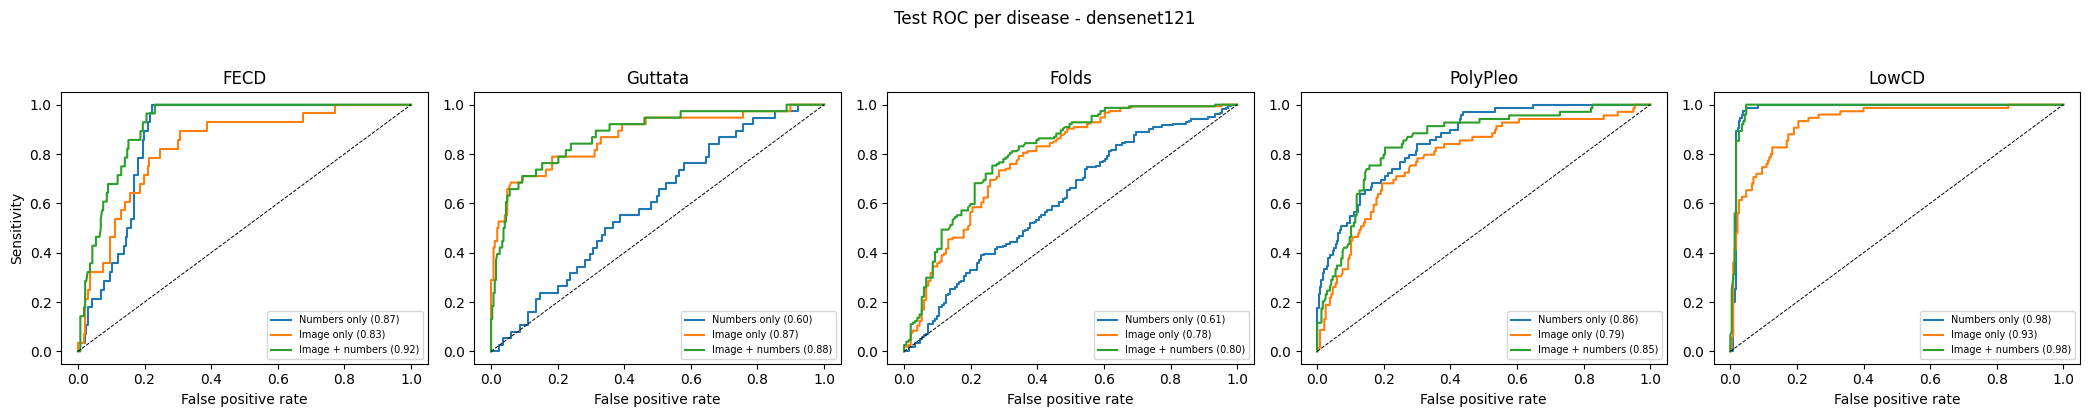

In [13]:
fig, axes = plt.subplots(1, len(LABEL_COLS), figsize=(4.2 * len(LABEL_COLS), 4))
for j, lab in enumerate(LABEL_COLS):
    for name in ORDER:
        fpr, tpr, _ = roc_curve(Y_TE[:, j], P_TEST[name][:, j])
        axes[j].plot(fpr, tpr, label=f"{name} ({test_auc.loc[name, lab]:.2f})")
    axes[j].plot([0, 1], [0, 1], "k--", lw=0.7)
    axes[j].set(title=lab, xlabel="False positive rate"); axes[j].legend(fontsize=7)
axes[0].set_ylabel("Sensitivity")
plt.suptitle(f"Test ROC per disease - {BACKBONE}", y=1.03); plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "test_roc.png"), dpi=120, bbox_inches="tight"); plt.show()

## Cell 13 — Grad-CAM visualisations

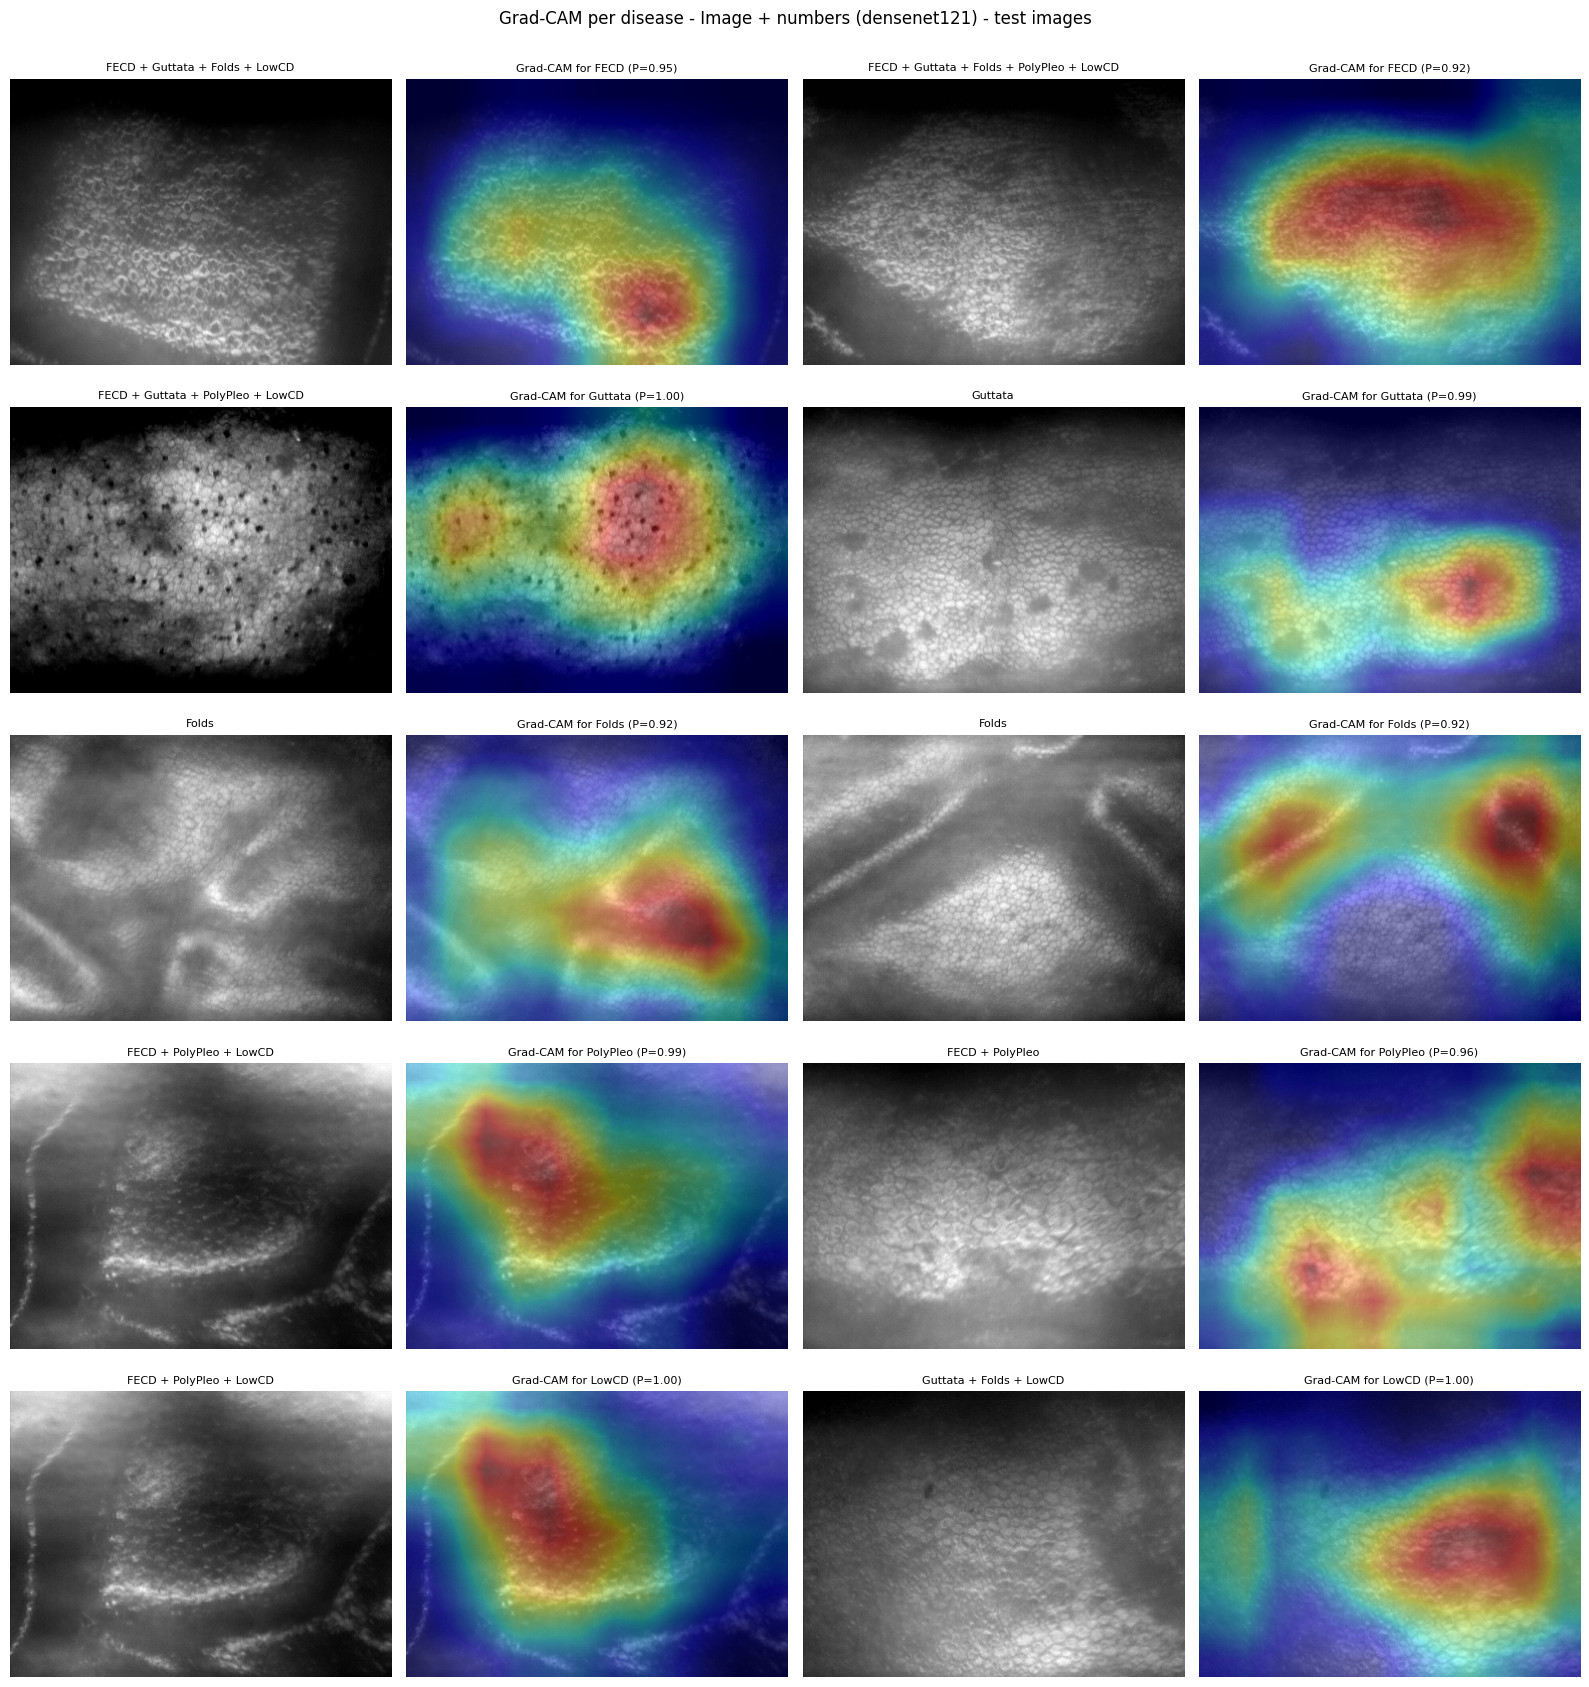

In [14]:
class GradCAM:
    def __init__(self, model):
        self.model, self.acts, self.grads = model.eval(), None, None
        def hook(m, i, o):
            self.acts = o; o.register_hook(lambda g: setattr(self, "grads", g))
        self.h = model.cam_layer.register_forward_hook(hook)
    def __call__(self, x, tab, label_idx):
        self.model.zero_grad()
        logit = self.model(x, tab)[0, label_idx]; logit.backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self.acts).sum(1)).squeeze().detach().float().cpu().numpy()
        cam = cv2.resize(cam, (IMG_W, IMG_H))
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), torch.sigmoid(logit).item()
    def remove(self): self.h.remove()

CAM_MODEL = "Image + numbers" if test_auc.loc["Image + numbers", "Macro AUC"] >= test_auc.loc["Image only", "Macro AUC"] else "Image only"
model, scale = final_models[CAM_MODEL]
ds = SPDataset(test_df, scale(test_df), False)
gc = GradCAM(model); P = P_TEST[CAM_MODEL]

fig, axes = plt.subplots(len(LABEL_COLS), 4, figsize=(16, 3.4 * len(LABEL_COLS)))
for j, lab in enumerate(LABEL_COLS):
    pos = np.where(Y_TE[:, j] == 1)[0]
    for c, i in enumerate(pos[np.argsort(-P[pos, j])][:2]):
        x, tab, _ = ds[i]
        cam, p = gc(x.unsqueeze(0).to(DEVICE), tab.unsqueeze(0).to(DEVICE), j)
        raw = cv2.resize(cv2.imread(ds.paths[i], 0), (IMG_W, IMG_H))
        axes[j, 2 * c].imshow(raw, cmap="gray"); axes[j, 2 * c].set_title(test_df.loc[i, "Combination"], fontsize=8)
        axes[j, 2 * c + 1].imshow(raw, cmap="gray"); axes[j, 2 * c + 1].imshow(cam, cmap="jet", alpha=0.4)
        axes[j, 2 * c + 1].set_title(f"Grad-CAM for {lab} (P={p:.2f})", fontsize=8)
    for a in axes[j]: a.axis("off")
gc.remove()
plt.suptitle(f"Grad-CAM per disease - {CAM_MODEL} ({BACKBONE}) - test images", y=1.0); plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "gradcam_per_disease.png"), dpi=110, bbox_inches="tight"); plt.show()

## Cell 14 — Save predictions and summary

In [15]:
out = test_df[["Tissue_ID", "Donor_Group", "Combination"] + LABEL_COLS].copy()
for name, tag in [("Numbers only", "Num"), ("Image only", "Img"), ("Image + numbers", "Fus")]:
    for j, lab in enumerate(LABEL_COLS):
        out[f"P_{tag}_{lab}"] = P_TEST[name][:, j]; out[f"Pred_{tag}_{lab}"] = PRED[name][:, j]
out.to_csv(os.path.join(FINAL_DIR, "test_predictions_all.csv"), index=False)

json.dump({"backbone": BACKBONE, "dataset": CSV_NAME, "n_train": len(train_df), "n_test": len(test_df),
           "thresholds": THRESH,
           "cv_auc": cv_auc.round(4).to_dict(orient="index"),
           "test_auc": test_auc.round(4).to_dict(orient="index"),
           "test_overall": {k: {m: round(float(v), 4) for m, v in d.items()} for k, d in overall_tab.items()},
           "image_only_epochs": [v["best_epoch"] for v in img_folds.values()],
           "fusion_epochs": [v["best_epoch"] for v in fus_folds.values()]},
          open(os.path.join(FINAL_DIR, "summary_final.json"), "w"), indent=2)
print("Saved everything to", FINAL_DIR)
print(os.listdir(FINAL_DIR))

Saved everything to /content/drive/MyDrive/CNN_results_v2/final_densenet121
['cv_auc_comparison.csv', 'Image_only.pt', 'Image_plus_numbers.pt', 'test_metrics_Numbers_only.csv', 'test_metrics_Image_only.csv', 'test_metrics_Image_plus_numbers.csv', 'test_auc_comparison.csv', 'test_auc_ci.csv', 'test_roc.png', 'gradcam_per_disease.png', 'test_predictions_all.csv', 'summary_final.json']
